In [5]:
IMAGE_DIR = Path("train_patches/images")
LABEL_DIR = Path("train_patches/labels")

image_files = sorted(IMAGE_DIR.glob("*.tif"))
label_files = sorted(LABEL_DIR.glob("*.tif"))


In [6]:

img_stems = [img.stem for img in image_files]
label_stems = [lbl.stem for lbl in label_files]

In [7]:
for img_ in img_stems:
    if img_ in label_stems:
        pass
    else:
        print(f"{img_} not in label_stems")
print('done')

done


## Import packages

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import tifffile as tiff
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

from torch.amp import GradScaler
from torch.amp import autocast

import segmentation_models_pytorch as smp

from torchvision.transforms import Compose, ToTensor
import albumentations as A

from PotsdamDataset import PotsdamDataset
from plot_functions import display_image_tensor, display_prediction, plot_train_val_losses, plot_train_val_metrics

#from training_loop import DiceFocalLoss, output_to_label, training_loop, train_epoch, validate, confusion_matrix_6x6, test_score
from training_loop_autocast import DiceFocalLoss, output_to_label, training_loop, train_epoch, validate, confusion_matrix_6x6, test_score

In [3]:
print("segmentation_models_pytorch version:", smp.__version__)

# FocalLoss in version 0.5.0 strictly expects raw logits

segmentation_models_pytorch version: 0.5.0


In [4]:
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA Version:", torch.version.cuda)

PyTorch Version: 2.3.1+cu118
CUDA Available: True
CUDA Version: 11.8


## Build vanilla U-Net model for semantic segmentation 

PyTorch expects images in (channels × height × width) format, or (C, H, W).
- Single Image: (C, H, W) — for example, a 3-channel RGB image is ``(3, H, W)``.
- Batch of Images: ``(B, C, H, W)`` — where B is the batch size

- Unlike libraries like Matplotlib, OpenCV, or NumPy/PIL arrays which typically use (H, W, C) (channels-last), PyTorch standardizes on "channels-first" (C, H, W) for its convolutional layers and transforms.

## Model architecture

- Design follows the original U-Net architecture with the exception that the downsampling are done in three stages instead of four, and the upsampling is done in three stages as well.
    - This choice was made in order to have less parameters to train

- Padding of 1 is applied to all 3x3 conv layers in order to keep image dimensions intact

- Skip-connections
    - Endoced data is concatenated to up-sampled data (both having same dimensions)  


In [8]:
class Vanilla_UNet(nn.Module):

    def __init__(self, img_dim:int, n_class:int, in_channels:int=3):

        super().__init__()
        
        self.n_class = n_class
        self.in_channels = in_channels
        self.out_channels = n_class
        self.img_dim = img_dim

        if self.img_dim  < 256:
            raise ValueError("Image dimension must be at least 256x256 for this U-Net implementation.")
        if self.img_dim % 256 != 0:
            raise ValueError("Image dimension must be a multiple of 256 for this U-Net implementation.")


        # Define the U-Net model using torch.nn


        # ---- MAXPOOLING ----
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)



        # ---- ENCODER ----
        
        # output used in skip connection
        self.encode_1 = nn.Sequential(
            nn.Conv2d(self.in_channels, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))
        
        # output used in skip connection
        self.encode_2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))
        
        # output used in skip connection
        self.encode_3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- BRIDGE ---- 
        # to connect encoder and decoder
        self.bridge = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- UP-SAMPLING ----
        # Upconvolution layers to upsample the feature maps back to the original image size
        self.upconv_3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)   # increase the spatial dimensions (64 --> 128)
        self.upconv_2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)   # increase the spatial dimensions (128 --> 256)
        self.upconv_1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)    # increase the spatial dimensions (256 --> 512)



        # ---- DECODER -----
        self.decode_3 = nn.Sequential(
            nn.Conv2d(512, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))

        self.decode_2 = nn.Sequential(
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))

        self.decode_1 = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- FINAL CONVOLUTION LAYER ----
        # Final layer to map to the desired number of classes
        self.final_conv = nn.Conv2d(64, self.out_channels, kernel_size=1)  




    def forward(self, x):

        # --- Encoder ---
        encoded_1 = self.encode_1(x)

        x = self.maxpool(encoded_1)

        encoded_2 = self.encode_2(x)

        x = self.maxpool(encoded_2)

        encoded_3 = self.encode_3(x)

        x = self.maxpool(encoded_3)



        # --- Bridge ---
        x = self.bridge(x)



        # --- Decoder ---
        
        # increase the spatial dimensions (64 --> 128)
        # decrease the number of channels (512 --> 256)
        x = self.upconv_3(x) 
        # Concatenate along the channel dimension 
        # dim=1 since PyTorch uses (N,C,H,W) format, where N is batch size, C is channels, H is height, W is width
        # number of channels after concatenation will be 256 (from upconv_3) + 256 (from encoded_3) = 512
        x = torch.cat((encoded_3, x), dim=1)

        x = self.decode_3(x)



        # increase the spatial dimensions (128 --> 256)
        # decrease the number of channels (256 --> 128)
        x = self.upconv_2(x)
        # number of channels after concatenation will be 128 (from upconv_2) + 128 (from encoded_2) = 256
        x = torch.cat((encoded_2, x), dim=1)
        
        x = self.decode_2(x)



        # increase the spatial dimensions (256 --> 512)
        # decrease the number of channels (128 --> 64)
        x = self.upconv_1(x)

        # number of channels after concatenation will be 64 (from upconv_1) + 64 (from encoded_1) = 128
        x = torch.cat((encoded_1, x), dim=1)
        
        x = self.decode_1(x)



        # --- Final layer --- 
        # to map to the desired number of classes
        x = self.final_conv(x)

        return x


# Initialize datasets and dataloaders

In [9]:
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5), ])


small_train_dataset = PotsdamDataset(root="./small_train_patches", transform=train_transform)
small_val_dataset = PotsdamDataset(root="./small_val_patches", transform=None)

small_train_loader = DataLoader(small_train_dataset, batch_size=16, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
small_val_loader = DataLoader(small_val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)

In [10]:
print(f"The example dataset is: {small_train_dataset}")
print(f"The example dataset type is: {type(small_train_dataset)}")
number_of_samples = len(small_train_dataset)
print(f"The number of samples is: {number_of_samples}")

img, label = small_train_dataset[200]

print(type(img), type(label))
print(img.dtype, label.dtype)
print(img.shape, label.shape)


The example dataset is: <PotsdamDataset.PotsdamDataset object at 0x7de2d8f2edd0>
The example dataset type is: <class 'PotsdamDataset.PotsdamDataset'>
The number of samples is: 350
<class 'torch.Tensor'> <class 'torch.Tensor'>
torch.float32 torch.int64
torch.Size([3, 512, 512]) torch.Size([512, 512])


Image shape: torch.Size([3, 512, 512])  
Label shape: torch.Size([512, 512])


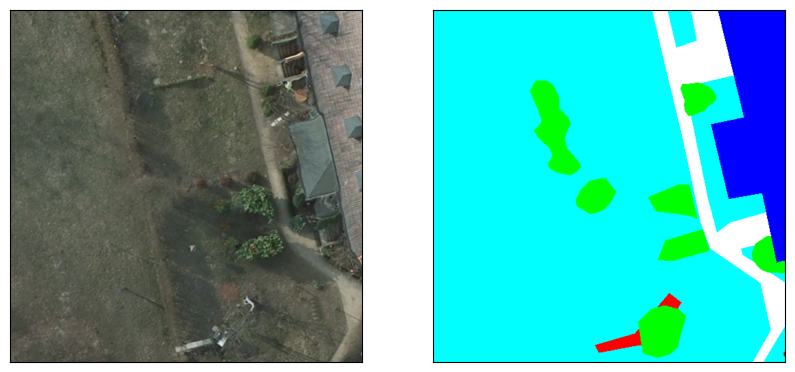

In [11]:
img, label = small_train_dataset[3]

print(f"Image shape: {img.shape}  \nLabel shape: {label.shape}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
display_image_tensor(axes[0], img)
display_image_tensor(axes[1], label)


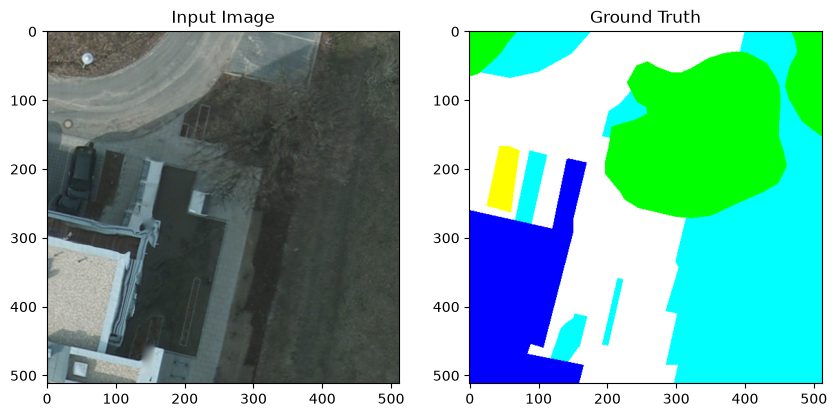

In [12]:
img, label = small_train_dataset.get_tif_by_id("2_12_512_1024")

plt.subplots(1, 2, figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Input Image')
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(label)
plt.title('Ground Truth')
plt.show()

# Training starts

In [13]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

In [14]:
print(torch.cuda.memory_allocated() / 1024**3)
print(torch.cuda.memory_reserved() / 1024**3)

0.0
0.0


In [15]:
print(torch.cuda.memory_summary())

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |      0 B   |
|       from small pool |      0 B   |      0 B   |      0 B   |      0 B   |
|---------------------------------------------------------------------------|
| Active memory         |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |

In [16]:
# OBS! 
# model is named "small_model"

small_model = Vanilla_UNet(img_dim=512, n_class=6, in_channels=3)

optimizer = optim.Adam(small_model.parameters(), lr=0.001)
loss_fn = DiceFocalLoss(w1=1, w2=1)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.4, patience=5, min_lr=1e-6)

num_epochs = 30


print(small_model.__class__.__name__)


# model, train_losses, train_accs, val_losses, val_accs
small_model, train_metrics, val_metrics = training_loop(
        small_model, optimizer, loss_fn, small_train_loader, small_val_loader, num_epochs, scheduler=scheduler, print_every=None)

Vanilla_UNet
Starting training


/home/edvard_edsgard/conda/envs/dml/lib/python3.11/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:84.)
  return F.conv2d(input, weight, bias, self.stride,


Epoch 1/30: 
Avg. Train loss: 2.802,  Train mean IoU: 0.112, Learning Rate: 0.00100, 
Avg. Val. loss: 3.018, Val. mean IoU: 0.093

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.1053
  -> Class 1 IoU: 0.2030
  -> Class 2 IoU: 0.0010
  -> Class 3 IoU: 0.2257
  -> Class 4 IoU: 0.0240
  -> Class 5 IoU: 0.0000

Epoch 2/30: 
Avg. Train loss: 2.281,  Train mean IoU: 0.184, Learning Rate: 0.00100, 
Avg. Val. loss: 2.376, Val. mean IoU: 0.239

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.4086
  -> Class 1 IoU: 0.3535
  -> Class 2 IoU: 0.5792
  -> Class 3 IoU: 0.0000
  -> Class 4 IoU: 0.0930
  -> Class 5 IoU: 0.0004

Epoch 3/30: 
Avg. Train loss: 1.942,  Train mean IoU: 0.275, Learning Rate: 0.00100, 
Avg. Val. loss: 2.196, Val. mean IoU: 0.323

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.6468
  -> Class 1 IoU: 0.5522
  -> Class 2 IoU: 0.5851
  -> Class 3 IoU: 0.0054
  -> Class 4 IoU: 0.1475
  -> Class 5 IoU: 0.0000



KeyboardInterrupt: 

In [ ]:
# try to continue training
# epoch 65 + 30

# Plots after XX epochs 


In [ ]:
train_loss = 
val_loss = 

plot_train_val_losses()


In [ ]:
plot_train_val_metrics(train_metrics, val_metrics, fig_size=(12,4.5))

In [ ]:
# small model run 2 - after 65 epochs

display_prediction(small_model, small_val_dataset, 5, fig_size=(11, 4))